In [1]:
import numpy as np
import pickle
import json
import glob
import os
import time

from POSEIDON.core import (create_star, create_planet, define_model,
                            make_atmosphere, compute_spectrum, wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

print("POSEIDON imports OK")

/Users/anushreeupasham/miniconda3/envs/poseidon_env/lib/python3.12/site-packages/pysynphot/refs.py:117: UserWarning: No graph or component tables found; functionality will be SEVERELY crippled. No files found for /Users/anushreeupasham/Desktop/POSEIDON/inputs/stellar_grids/mtab/*_tmg.fits
  warnings.warn('No graph or component tables found; '
/Users/anushreeupasham/miniconda3/envs/poseidon_env/lib/python3.12/site-packages/pysynphot/refs.py:124: UserWarning: No thermal tables found, no thermal calculations can be performed. No files found for /Users/anushreeupasham/Desktop/POSEIDON/inputs/stellar_grids/mtab/*_tmt.fits
  warnings.warn('No thermal tables found, '


POSEIDON imports OK


In [2]:
def load_survey_planets(base_dir="freckll_survey_output", limit=None):
    """
    Load survey planets: params + disequilibrium VMR.
    Returns (records, vmr_array) where records is a list of param dicts
    and vmr_array has shape (n_planets, n_species, n_layers).
    Set limit=N to load only the first N planets (for verification runs).
    """
    planet_dirs = sorted(glob.glob(f"{base_dir}/planet_*"))
    if limit is not None:
        planet_dirs = planet_dirs[:limit]

    records, vmr_list = [], []
    for pdir in planet_dirs:
        with open(f"{pdir}/params.json") as f:
            params = json.load(f)
        params["planet_dir"] = pdir
        vmr = np.load(f"{pdir}/final_vmr.npy")
        records.append(params)
        vmr_list.append(vmr)

    vmr_array = np.array(vmr_list)
    return records, vmr_array


def load_species_names(path="species_names.npy"):
    """Load the FRECKLL network species names (order matches the VMR rows)."""
    return np.load(path).tolist()


def find_species_index(names_list, name):
    """Return the row index of a species in the VMR array by name."""
    for idx, n in enumerate(names_list):
        if n == name:
            return idx
    raise ValueError(f"Species {name} not found in list")


def load_opacity(path="opacities_created/opac_eq_chemistry.pickle"):
    """Load the POSEIDON opacity database."""
    with open(path, "rb") as f:
        return pickle.load(f)


def load_wl_binned(path="equi_chem_data/wl_binned.npy"):
    """Load the target (instrument-resolution) wavelength grid for binning."""
    return np.load(path)

In [3]:
records, disequilibrium_vmr = load_survey_planets(limit=10)
species_names = load_species_names()

print(f"Loaded {len(records)} planets, VMR shape: {disequilibrium_vmr.shape}")
print(f"Species count: {len(species_names)}")
print(f"First planet params: {records[0]}")

Loaded 10 planets, VMR shape: (10, 44, 100)
Species count: 44
First planet params: {'Teq_K': 2389.681331101101, 'Rp_Rj': 1.469383934667544, 'Mp_Mj': 3.729786497683026, 'Rstar_Rs': 1.0206882105286554, 'kzz_cm2_s': 10000000000.0, 'success': True, 'planet_dir': 'freckll_survey_output/planet_0000'}


In [4]:
species_names = load_species_names()

target_species = ["H2O", "CH4", "CO", "CO2", "NH3"]
species_idx = {name: find_species_index(species_names, name) for name in target_species}
print("Species indices:", species_idx)

# pressure grid + the reversal fix for POSEIDON
pressure_bar = np.logspace(3, -6, 100)
pressure_bar_fixed = pressure_bar[::-1]

# high-res wavelength grid for spectrum computation
wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)

# load opacity + binned wl grid
opac = load_opacity()
wl_binned = load_wl_binned()

# model + star
model = define_model("disequil_model", ["H2", "He"], target_species,
                      PT_profile="file_read", X_profile="file_read")
star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)

print(f"wl_highres: {len(wl_highres)} points, {wl_highres.min():.2f}-{wl_highres.max():.2f} um")
print(f"wl_binned: {len(wl_binned)} points, {wl_binned.min():.2f}-{wl_binned.max():.2f} um")
print("Model, star, opacity loaded.")

Species indices: {'H2O': 35, 'CH4': 32, 'CO': 34, 'CO2': 27, 'NH3': 31}
wl_highres: 48283 points, 0.40-10.00 um
wl_binned: 52 points, 0.55-7.28 um
Model, star, opacity loaded.


In [ ]:
# species_names = load_species_names()

# target_species = ["H2O", "CH4", "CO", "CO2", "NH3"]
# species_idx = {name: find_species_index(species_names, name) for name in target_species}
# print("Species indices:", species_idx)

# pressure_bar = np.logspace(3, -6, 100)

# wl_min, wl_max, R_highres = 0.4, 10.0, 15000
# wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)

# opac = load_opacity()
# wl_binned = load_wl_binned()

# model = define_model("disequil_model", ["H2", "He"], target_species,
#                       PT_profile="file_read", X_profile="file_read")
# star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)

# print(f"wl_highres: {len(wl_highres)} points, {wl_highres.min():.2f}-{wl_highres.max():.2f} um")
# print(f"wl_binned: {len(wl_binned)} points, {wl_binned.min():.2f}-{wl_binned.max():.2f} um")
# print("Setup complete (no pressure reversal).")

Species indices: {'H2O': 35, 'CH4': 32, 'CO': 34, 'CO2': 27, 'NH3': 31}


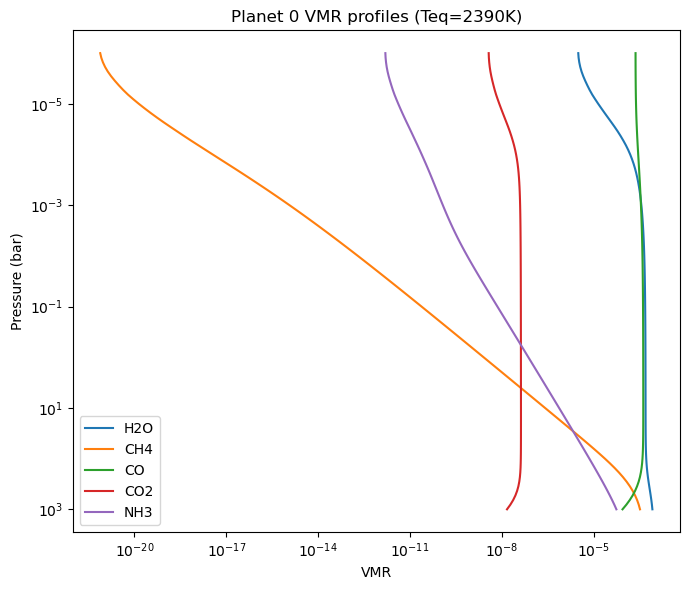

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
colors = {"H2O": "tab:blue", "CH4": "tab:orange", "CO": "tab:green",
          "CO2": "tab:red", "NH3": "tab:purple"}

for name in target_species:
    idx = species_idx[name]
    ax.plot(disequilibrium_vmr[0][idx, :], pressure_bar, color=colors[name], label=name)

ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_yaxis()   # low pressure (top of atmosphere) at top of plot
ax.set_xlabel("VMR")
ax.set_ylabel("Pressure (bar)")
ax.set_title(f"Planet 0 VMR profiles (Teq={records[0]['Teq_K']:.0f}K)")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
def build_X_input(vmr_array):
    """
    Build POSEIDON's X_input: [H2, He, H2O, CH4, CO, CO2, NH3], all deep-first
    (same order as pressure_bar, no reversal). H2/He are fixed bulk fill values.
    """
    n = len(pressure_bar)
    return np.array([
        np.full(n, 0.83),                      # H2 bulk
        np.full(n, 0.17),                      # He bulk
        vmr_array[species_idx["H2O"], :],
        vmr_array[species_idx["CH4"], :],
        vmr_array[species_idx["CO"], :],
        vmr_array[species_idx["CO2"], :],
        vmr_array[species_idx["NH3"], :],
    ])


def generate_spectrum(record, vmr_array):
    """
    Full forward model for one planet: params + VMR -> high-res transmission spectrum.
    Returns (spectrum, is_physical). spectrum is None if not physical.
    """
    R_p = record["Rp_Rj"] * R_J
    M_p = record["Mp_Rj"] * M_J if "Mp_Rj" in record else record["Mp_Mj"] * M_J
    planet = create_planet("planet", R_p, mass=M_p, T_eq=record["Teq_K"])

    T_input = np.full(len(pressure_bar), record["Teq_K"])   # isothermal, deep-first
    X_input = build_X_input(vmr_array)
    P_ref = 10.0

    atmosphere = make_atmosphere(planet, model, pressure_bar, P_ref, R_p,
                                  T_input=T_input, X_input=X_input)
    if not atmosphere["is_physical"]:
        return None, False

    spectrum = compute_spectrum(planet, star, model, atmosphere, opac, wl_highres,
                                spectrum_type="transmission")
    return spectrum, True


# --- verify on the first planet ---
spec, physical = generate_spectrum(records[0], disequilibrium_vmr[0])
if physical:
    print(f"Planet 0: is_physical=True")
    print(f"  mean={spec.mean():.3e}, std={spec.std():.3e}, "
          f"std/mean={spec.std()/spec.mean():.2e}")
    print(f"  nan={np.any(np.isnan(spec))}, inf={np.any(np.isinf(spec))}")
else:
    print("Planet 0: NOT physical")

Planet 0: is_physical=True
  mean=2.347e-02, std=2.268e-04, std/mean=9.67e-03
  nan=False, inf=False


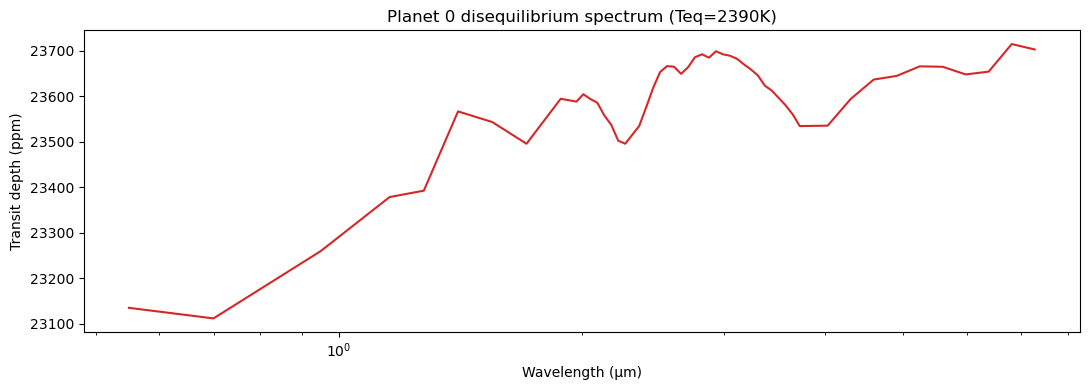

In [7]:
import spectres

if physical:
    spec_binned = spectres.spectres(wl_binned, wl_highres, spec, verbose=False)

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(wl_binned, spec_binned * 1e6, color="tab:red")
    ax.set_xscale("log")
    ax.set_xlabel("Wavelength (μm)")
    ax.set_ylabel("Transit depth (ppm)")
    ax.set_title(f"Planet 0 disequilibrium spectrum (Teq={records[0]['Teq_K']:.0f}K)")
    plt.tight_layout()
    plt.show()

In [8]:
import os
import time
import numpy as np
import spectres

records_all, disequilibrium_vmr_all = load_survey_planets(limit=None)
n_total = len(records_all)
print(f"Loaded {n_total} planets")

OUT_DIR = "disequil_spectra_output_8k"
os.makedirs(OUT_DIR, exist_ok=True)

# resumable: skip planets already saved
already_done = set(int(f.split("_")[1].split(".")[0])
                   for f in os.listdir(OUT_DIR) if f.startswith("spec_"))
print(f"{len(already_done)} already done, {n_total - len(already_done)} remaining")

success = []
t0 = time.time()
n_processed = 0

for i in range(n_total):
    if i in already_done:
        continue
    try:
        spec, physical = generate_spectrum(records_all[i], disequilibrium_vmr_all[i])
        if physical and not (np.any(np.isnan(spec)) or np.any(np.isinf(spec))):
            sb = spectres.spectres(wl_binned, wl_highres, spec, verbose=False)
            np.save(os.path.join(OUT_DIR, f"spec_{i:05d}.npy"), sb)
            success.append(i)
    except Exception:
        pass

    n_processed += 1
    if n_processed % 100 == 0:
        rate = (time.time() - t0) / n_processed
        remaining = (n_total - len(already_done) - n_processed) * rate / 60
        print(f"{i}/{n_total}  |  {rate:.1f}s/planet  |  ~{remaining:.0f} min left", flush=True)

print(f"\nDone. {len(success)} new spectra in {(time.time()-t0)/60:.1f} min")

Loaded 8426 planets
43 already done, 8383 remaining
142/8426  |  0.6s/planet  |  ~85 min left
242/8426  |  0.6s/planet  |  ~84 min left
342/8426  |  0.6s/planet  |  ~83 min left
442/8426  |  0.6s/planet  |  ~80 min left
542/8426  |  0.6s/planet  |  ~80 min left
642/8426  |  0.6s/planet  |  ~78 min left
742/8426  |  0.6s/planet  |  ~74 min left
842/8426  |  0.6s/planet  |  ~72 min left
942/8426  |  0.6s/planet  |  ~69 min left
1042/8426  |  0.5s/planet  |  ~67 min left
1142/8426  |  0.5s/planet  |  ~65 min left
1242/8426  |  0.5s/planet  |  ~63 min left
1342/8426  |  0.5s/planet  |  ~61 min left
1442/8426  |  0.5s/planet  |  ~60 min left
1542/8426  |  0.5s/planet  |  ~58 min left
1642/8426  |  0.5s/planet  |  ~57 min left
1742/8426  |  0.5s/planet  |  ~56 min left
1842/8426  |  0.5s/planet  |  ~55 min left
1942/8426  |  0.5s/planet  |  ~54 min left
2042/8426  |  0.5s/planet  |  ~54 min left
2142/8426  |  0.5s/planet  |  ~54 min left
2242/8426  |  0.5s/planet  |  ~53 min left
2342/8426  

In [ ]:
import time
import os
import numpy as np
import spectres

OUT_DIR = "disequil_spectra_output"
os.makedirs(OUT_DIR, exist_ok=True)

# time just 10 planets serially, no multiprocessing at all
t0 = time.time()
n_ok = 0
for i in range(10):
    spec, physical = generate_spectrum(records[i], disequilibrium_vmr[i])
    if physical:
        spec_binned = spectres.spectres(wl_binned, wl_highres, spec, verbose=False)
        np.save(os.path.join(OUT_DIR, f"spec_{i:05d}.npy"), spec_binned)
        n_ok += 1

elapsed = time.time() - t0
print(f"10 planets in {elapsed:.1f}s = {elapsed/10:.1f}s per planet")
print(f"Projected for 8426: {elapsed/10 * 8426 / 60:.0f} min = {elapsed/10 * 8426 / 3600:.1f} hours")
print(f"Success: {n_ok}/10")

10 planets in 3.7s = 0.4s per planet
Projected for 8426: 52 min = 0.9 hours
Success: 10/10
